# 04b. Modèle du décrochage au primaire

Sentinelle Scolaire, défi 1.

La cible est le **taux d'abandon du primaire** de la province entre l'année t et t+1, pour l'ensemble des élèves et par sexe. Seules les cibles observées hors rupture de scolarisation servent à apprendre et à évaluer (notebook 04a).

Le modèle a trois briques :

1. **Prévision** du taux d'abandon à 1, 2 et 3 ans, avec un intervalle à 80 % calibré. Six modèles sont comparés dans le temps ; le plus simple qui fait au moins aussi bien que les autres est retenu.
2. **Explication** : pourquoi une province a un niveau habituel d'abandon élevé (contribution de chaque variable, en points de taux).
3. **Alerte de rupture** : risque que la scolarisation s'effondre (variation des effectifs de plus de 30 %).

**Validation dans le temps.** Pour une cible de l'année Y, l'apprentissage n'utilise que des cibles connues à la date des variables. Trois plis servent aux choix ; le test final (2024-2025 pour l'ensemble, 2023-2024 par sexe) n'est utilisé qu'une fois.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentinelle.analyse import executer_exploration, executer_modelisation

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})
SOURCE = "Source : annuaires DGESS, base apurée du défi 1. Calculs des auteurs."
COULEURS = {"reference_annee_precedente": "#bdbcb6", "reference_niveau_habituel": "#1f3a5f",
            "elastic_net": "#2e9e55", "ridge_effet_province": "#8a8984", "lightgbm": "#e8935a",
            "moyenne_elastic_lightgbm": "#b5446e"}

In [2]:
executer_exploration()
tables = executer_modelisation()

## 1. Brique 1 : quel modèle prévoit le mieux ?

Erreur absolue moyenne (points de taux), corrélation de rang entre taux prévus et observés, et part des provinces du quintile le plus à risque effectivement retrouvées. Les modèles appris prédisent l'écart au niveau habituel de la province, diminué du choc commun à toutes les provinces l'année de la cible (une crise nationale n'est prévisible par aucune variable provinciale).

In [3]:
s = tables["synthese_modeles_ensemble"]
s[s["horizon"] == 1].pivot_table(index="modele", columns="role",
                                 values=["erreur_absolue_moyenne", "correlation_rang", "rappel_quintile_le_plus_a_risque"])

correlation_rang            erreur_absolue_moyenne            rappel_quintile_le_plus_a_risque           
role                              sélection test final              sélection test final                        sélection test final
modele                                                                                                                              
elastic_net                           0.537      0.557                  6.360      3.401                            0.548      0.750
lightgbm                              0.536      0.557                  7.385      3.658                            0.506      0.625
moyenne_elastic_lightgbm              0.536      0.551                  6.768      3.471                            0.506      0.750
reference_annee_precedente            0.340      0.363                  7.825      4.658                            0.506      0.625
reference_niveau_habituel             0.541      0.557                  6.348      3.426                            0.548      0.750
ridge_effet_province                  0.533      0.479                  7.527      6.868                            0.548      0.750

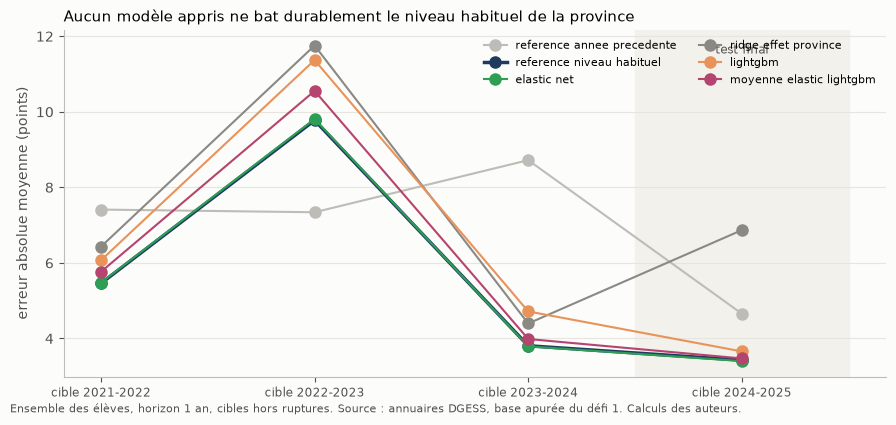

In [4]:
e = tables["evaluation_plis_ensemble"]
e1 = e[e["horizon"] == 1]
fig, ax = plt.subplots(figsize=(9, 4.2))
annees = sorted(e1["annee_cible"].unique())
for m, couleur in COULEURS.items():
    serie = e1[e1["modele"] == m].set_index("annee_cible")["erreur_absolue_moyenne"].reindex(annees)
    ax.plot(range(len(annees)), serie.values, marker="o", ms=8, lw=2.5 if m == "reference_niveau_habituel" else 1.5,
            color=couleur, label=m.replace("_", " "))
ax.axvspan(len(annees) - 1.5, len(annees) - 0.5, color="#f2f1ec", zorder=0)
ax.text(len(annees) - 1, ax.get_ylim()[1] * 0.97, "test final", ha="center", va="top", fontsize=8.5, color="#52514e")
ax.set_xticks(range(len(annees)), [f"cible {a}" for a in annees], fontsize=8.5)
ax.set_ylabel("erreur absolue moyenne (points)")
ax.grid(axis="y", color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax.set_title("Aucun modèle appris ne bat durablement le niveau habituel de la province", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Ensemble des élèves, horizon 1 an, cibles hors ruptures. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

**Lecture.** Les modèles appris gagnent un peu les années de crise et perdent les années calmes ; aucun ne fait mieux durablement que le niveau habituel de la province (moyenne de ses taux passés hors ruptures). Les variables provinciales ne prévoient pas les variations d'une année sur l'autre, qui sont surtout des chocs communs : la prévision retenue est donc le niveau habituel. Le même constat vaut par sexe :

In [5]:
s = tables["synthese_modeles_sexe"]
s[s["horizon"] == 1].pivot_table(index="modele", columns="role", values=["erreur_absolue_moyenne", "correlation_rang"])

correlation_rang            erreur_absolue_moyenne           
role                              sélection test final              sélection test final
modele                                                                                  
elastic_net                           0.549      0.660                  6.406      3.939
lightgbm                              0.460      0.641                  7.684      5.162
moyenne_elastic_lightgbm              0.509      0.661                  6.991      4.258
reference_annee_precedente            0.327      0.484                  7.212      8.831
reference_niveau_habituel             0.549      0.660                  6.386      3.938
ridge_effet_province                  0.473      0.614                  8.416      4.535

In [6]:
pd.concat({"ensemble": tables["reglages_ensemble"], "par sexe": tables["reglages_sexe"]})

,,alpha_elastic,alpha_ridge,modele_retenu
ensemble,0,3.0,3000.0,reference_niveau_habituel
par sexe,0,10.0,3000.0,reference_niveau_habituel


## 2. L'intervalle à 80 %

La marge est calibrée sur les erreurs hors échantillon des plis (prédiction conforme) ; la couverture est ensuite mesurée sur le test final, jamais utilisé avant. Elle doit être proche de 80 % ou au-dessus. La marge est large (environ ±10 points) parce que les plis comprennent les années de crise 2021-2023.

In [7]:
pd.concat({"ensemble": tables["intervalle_ensemble"], "par sexe": tables["intervalle_sexe"]})

horizon                     modele  marge_conforme  couverture_test_final  largeur_moyenne  lignes
ensemble 0        1  reference_niveau_habituel          10.031                  0.900           20.062      40
         1        2  reference_niveau_habituel          10.552                  0.900           21.104      40
         2        3  reference_niveau_habituel          10.063                  0.950           20.126      40
par sexe 0        1  reference_niveau_habituel           9.684                  0.859           19.368      64
         1        2  reference_niveau_habituel          13.162                  1.000           26.323      64
         2        3  reference_niveau_habituel           9.559                  0.812           19.117      64

## 3. Les prévisions 2025-2026

Classe de risque : *élevé* au-dessus du 80e centile des taux observés, *moyen* au-dessus de la médiane.

In [8]:
tables["seuils_classes_ensemble"]

,classe,taux_abandon_prevu
0,moyen à partir de (médiane),8.43
1,élevé à partir de (80e centile),14.16


In [9]:
tb = tables["tableau_de_bord_ensemble"]
tb[["province_nom", "region_nom", "taux_abandon_annee_des_variables", "taux_abandon_prevu", "borne_basse_80",
    "borne_haute_80", "classe_de_risque", "risque_de_rupture", "province_scindee"]].head(20)

,province_nom,region_nom,taux_abandon_annee_des_variables,taux_abandon_prevu,borne_basse_80,borne_haute_80,classe_de_risque,risque_de_rupture,province_scindee
0,Loroum,Yaadga,34.350,25.43,16.28,34.57,élevé,élevé,False
1,Karo-Peli,Soum,18.680,24.89,15.75,34.03,élevé,élevé,True
2,Djelgodji,Soum,18.680,24.39,15.25,33.53,élevé,élevé,True
3,Seno,Liptako,18.310,24.24,15.10,33.38,élevé,élevé,False
4,Yagha,Liptako,19.370,23.68,14.54,32.83,élevé,élevé,False
5,Oudalan,Liptako,18.680,18.56,9.42,27.70,élevé,élevé,False
6,Dyamongou,Tapoa,9.745,17.72,8.58,26.86,élevé,élevé,True
7,Gobnangou,Tapoa,9.745,17.72,8.58,26.86,élevé,élevé,True
8,Kossin,Sourou,-1.370,16.25,7.11,25.39,élevé,faible,False
9,Namentenga,Koulse,17.180,15.57,6.43,24.71,élevé,moyen,False


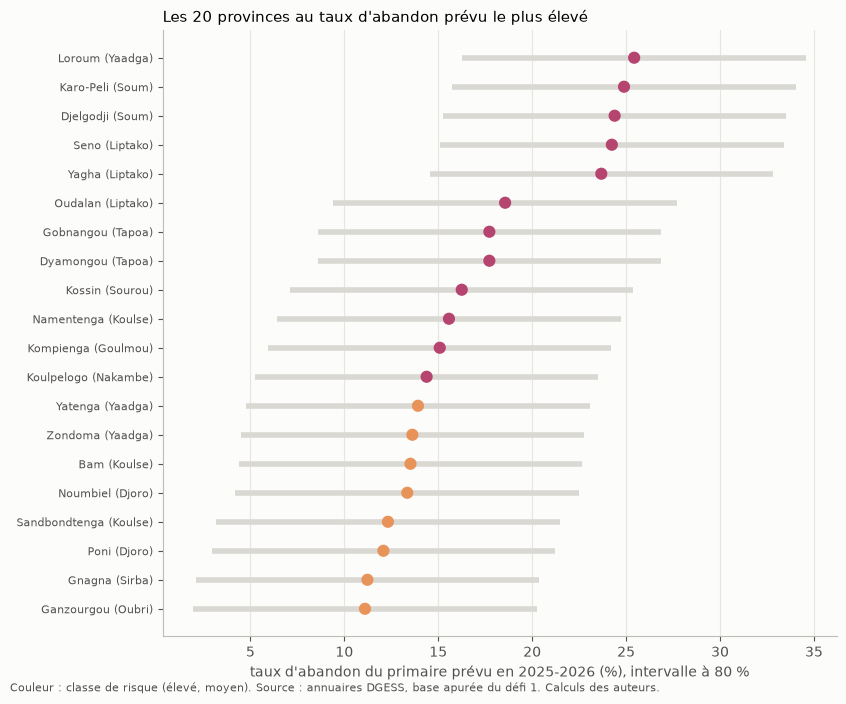

In [10]:
t = tb.sort_values("taux_abandon_prevu").tail(20)
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(t))
couleur = t["classe_de_risque"].map({"élevé": "#b5446e", "moyen": "#e8935a", "faible": "#8a8984"})
ax.hlines(y, t["borne_basse_80"].clip(lower=0), t["borne_haute_80"], color="#d9d8d3", lw=4)
ax.scatter(t["taux_abandon_prevu"], y, color=couleur, s=60, zorder=3)
ax.set_yticks(y, t["province_nom"] + " (" + t["region_nom"] + ")", fontsize=8)
ax.set_xlabel("taux d'abandon du primaire prévu en 2025-2026 (%), intervalle à 80 %")
ax.grid(axis="x", color="#e6e5e0")
ax.set_title("Les 20 provinces au taux d'abandon prévu le plus élevé", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Couleur : classe de risque (élevé, moyen). " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 4. Brique 2 : pourquoi ces provinces ?

Le niveau habituel de chaque province est expliqué par ses variables moyennes (sans les variables de persistance). La qualité est mesurée en prédisant des provinces que le modèle n'a pas vues.

In [11]:
pd.concat({"ensemble": tables["explication_validation_ensemble"], "par sexe": tables["explication_validation_sexe"]})

modele  unites  r2_provinces_non_vues  correlation_rang_provinces_non_vues  erreur_absolue_moyenne  retenu
ensemble 0     lightgbm      43                  0.490                                0.730                   2.267    True
         1  elastic_net      43                  0.319                                0.734                   2.596   False
par sexe 0     lightgbm      86                  0.422                                0.756                   2.957    True
         1  elastic_net      86                  0.291                                0.711                   3.093   False

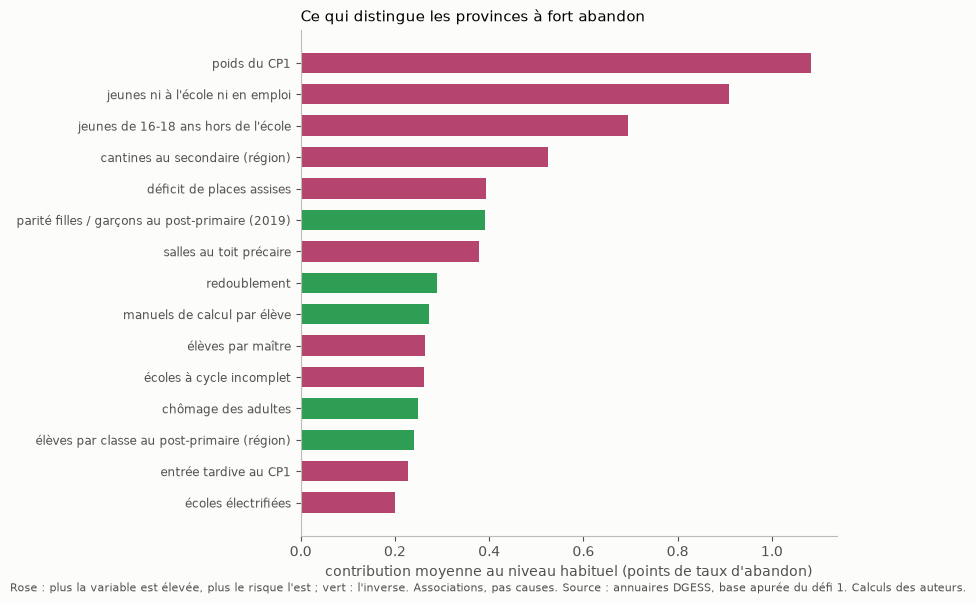

In [12]:
imp = tables["explication_importance_ensemble"].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
couleur = imp["sens"].map(lambda s: "#b5446e" if "plus le risque est élevé" in s else
                          ("#2e9e55" if "plus le risque est faible" in s else "#8a8984"))
ax.barh(imp["libelle"], imp["contribution_absolue_moyenne_points"], color=couleur, height=0.65)
ax.set_xlabel("contribution moyenne au niveau habituel (points de taux d'abandon)")
ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Ce qui distingue les provinces à fort abandon", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Rose : plus la variable est élevée, plus le risque l'est ; vert : l'inverse. "
         "Associations, pas causes. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

In [13]:
tables["explication_importance_ensemble"].head(15)

,variable,libelle,contribution_absolue_moyenne_points,sens
0,part_cp1,poids du CP1,1.083,"plus elle est élevée, plus le risque est élevé"
1,ni_ecole_ni_emploi_15_24_province,jeunes ni à l'école ni en emploi,0.910,"plus elle est élevée, plus le risque est élevé"
2,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,0.695,"plus elle est élevée, plus le risque est élevé"
3,part_etab_post_primaire_secondaire_publics_cantine_region,cantines au secondaire (région),0.524,"plus elle est élevée, plus le risque est élevé"
4,deficit_places_pour_100_eleves_primaire,déficit de places assises,0.393,"plus elle est élevée, plus le risque est élevé"
5,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),0.392,"plus elle est élevée, plus le risque est faible"
6,part_salles_primaire_toit_precaire,salles au toit précaire,0.379,"plus elle est élevée, plus le risque est élevé"
7,redoublement_primaire_precedent,redoublement,0.290,"plus elle est élevée, plus le risque est faible"
8,manuels_calcul_par_eleve_primaire,manuels de calcul par élève,0.273,"plus elle est élevée, plus le risque est faible"
9,eleves_par_maitre_primaire,élèves par maître,0.264,"plus elle est élevée, plus le risque est élevé"


In [14]:
tb[["province_nom", "taux_abandon_prevu", "facteur_1", "facteur_2", "facteur_3", "frein_principal"]].head(15)

,province_nom,taux_abandon_prevu,facteur_1,facteur_2,facteur_3,frein_principal
0,Loroum,25.43,jeunes ni à l'école ni en emploi (+2.1 pt),poids du CP1 (+2.0 pt),jeunes de 16-18 ans hors de l'école (+1.5 pt),chômage des adultes (-0.2 pt)
1,Karo-Peli,24.89,jeunes ni à l'école ni en emploi (+2.1 pt),poids du CP1 (+2.1 pt),jeunes de 16-18 ans hors de l'école (+1.5 pt),parité filles / garçons au post-primaire (2019) (-0.4 pt)
2,Djelgodji,24.39,jeunes ni à l'école ni en emploi (+2.1 pt),poids du CP1 (+2.1 pt),jeunes de 16-18 ans hors de l'école (+1.5 pt),entrée tardive au CP1 (-0.3 pt)
3,Seno,24.24,poids du CP1 (+2.1 pt),jeunes ni à l'école ni en emploi (+2.1 pt),jeunes de 16-18 ans hors de l'école (+1.5 pt),écoles à cycle incomplet (-0.3 pt)
4,Yagha,23.68,jeunes ni à l'école ni en emploi (+2.0 pt),poids du CP1 (+2.0 pt),jeunes de 16-18 ans hors de l'école (+1.3 pt),écoles électrifiées (-0.6 pt)
5,Oudalan,18.56,jeunes ni à l'école ni en emploi (+2.0 pt),poids du CP1 (+2.0 pt),jeunes de 16-18 ans hors de l'école (+1.4 pt),écoles électrifiées (-0.6 pt)
6,Dyamongou,17.72,jeunes de 16-18 ans hors de l'école (+1.5 pt),poids du CP1 (+1.3 pt),salles au toit précaire (+1.0 pt),jeunes ni à l'école ni en emploi (-0.5 pt)
7,Gobnangou,17.72,poids du CP1 (+1.3 pt),salles au toit précaire (+1.0 pt),parité filles / garçons au post-primaire (2019) (+0.8 pt),jeunes ni à l'école ni en emploi (-0.4 pt)
8,Kossin,16.25,jeunes de 16-18 ans hors de l'école (+1.5 pt),poids du CP1 (+1.3 pt),déficit de places assises (+0.9 pt),jeunes ni à l'école ni en emploi (-0.5 pt)
9,Namentenga,15.57,jeunes ni à l'école ni en emploi (+2.0 pt),poids du CP1 (+1.9 pt),jeunes de 16-18 ans hors de l'école (+1.3 pt),entrée tardive au CP1 (-0.4 pt)


## 5. Par sexe

In [15]:
tables["explication_importance_sexe"].head(12)

,variable,libelle,contribution_absolue_moyenne_points,sens
0,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,1.166,"plus elle est élevée, plus le risque est élevé"
1,rapport_cm2_cp1,rapport CM2 / CP1,0.858,"plus elle est élevée, plus le risque est faible"
2,achevement_post_primaire_province,achèvement du post-primaire,0.701,"plus elle est élevée, plus le risque est faible"
3,eleves_par_maitre_primaire,élèves par maître,0.493,"plus elle est élevée, plus le risque est élevé"
4,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),0.492,"plus elle est élevée, plus le risque est faible"
5,part_eleves_primaire_12_ans_et_plus,élèves de 12 ans et plus,0.462,"plus elle est élevée, plus le risque est faible"
6,abandons_primaire_orpaillage_pour_1000_region,abandons pour l'orpaillage (région),0.367,"plus elle est élevée, plus le risque est élevé"
7,achevement_primaire_province,achèvement du primaire,0.360,"plus elle est élevée, plus le risque est faible"
8,fille,fille,0.346,"plus elle est élevée, plus le risque est faible"
9,ips_tbs_primaire_region,parité de scolarisation (région),0.344,"plus elle est élevée, plus le risque est faible"


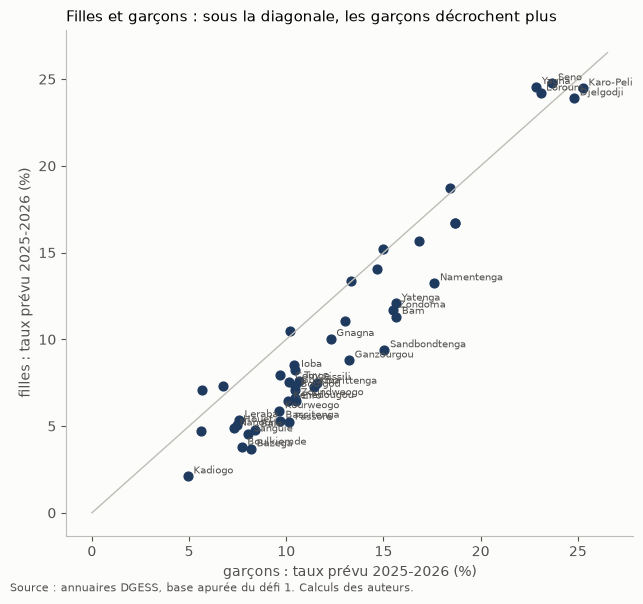

In [16]:
ts = tables["tableau_de_bord_sexe"]
large = ts.pivot_table(index="province_nom", columns="sexe", values="taux_abandon_prevu")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(large["G"], large["F"], color="#1f3a5f", s=40)
borne = [0, max(large.max()) * 1.05]
ax.plot(borne, borne, color="#bdbcb6", lw=1)
for nom, r in large.iterrows():
    if abs(r["F"] - r["G"]) > 2 or r.max() > 20:
        ax.annotate(nom, (r["G"], r["F"]), xytext=(4, 2), textcoords="offset points", fontsize=7.5, color="#52514e")
ax.set_xlabel("garçons : taux prévu 2025-2026 (%)"); ax.set_ylabel("filles : taux prévu 2025-2026 (%)")
ax.set_title("Filles et garçons : sous la diagonale, les garçons décrochent plus", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 6. Brique 3 : l'alerte de rupture

Régression logistique pénalisée sur des signaux connus à la date t. Mesure : AUC (probabilité qu'une province en rupture ait un score plus élevé qu'une autre) et nombre de ruptures retrouvées dans le quart des provinces au score le plus élevé.

In [17]:
tables["evaluation_alerte_rupture"]

,annee_cible,role,provinces,ruptures,auc,ruptures_dans_le_quart_le_plus_a_risque
0,2021-2022,sélection,43,5,0.874,4
1,2022-2023,sélection,40,8,0.852,7
2,2023-2024,sélection,34,2,0.906,2
3,2024-2025,test final,42,2,0.962,2


In [18]:
tables["coefficients_alerte_rupture"]

,variable,libelle,coefficient_standardise
6,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,1.326
0,evolution_eleves_primaire,évolution des effectifs,-1.044
2,rupture_annee_precedente,rupture l'année précédente,-0.923
4,abandon_primaire_precedent,abandon de l'année,0.905
3,ruptures_passees,ruptures passées,0.422
5,abandons_primaire_orpaillage_pour_1000_region,abandons pour l'orpaillage (région),-0.406
1,baisse_effectifs,baisse des effectifs,-0.008


In [19]:
tables["alerte_rupture"].head(15)

,province_pcode,province_nom,region_nom,annee_prevue,score_rupture,risque_de_rupture
0,BF5902,Karo-Peli,Soum,2025-2026,0.995,élevé
1,BF6403,Yagha,Liptako,2025-2026,0.994,élevé
2,BF5901,Djelgodji,Soum,2025-2026,0.983,élevé
3,BF5401,Loroum,Yaadga,2025-2026,0.966,élevé
4,BF5802,Komandjari,Sirba,2025-2026,0.923,élevé
5,BF6402,Seno,Liptako,2025-2026,0.904,élevé
6,BF6001,Dyamongou,Tapoa,2025-2026,0.903,élevé
7,BF6401,Oudalan,Liptako,2025-2026,0.871,élevé
8,BF5801,Gnagna,Sirba,2025-2026,0.811,élevé
9,BF6002,Gobnangou,Tapoa,2025-2026,0.783,élevé


## Ce qu'il faut retenir

- **Le décrochage est structurel et persistant.** Le meilleur prévisionniste du taux d'abandon de l'an prochain est le niveau habituel de la province ; les modèles appris (elastic net, modèle mixte, LightGBM) ne font pas mieux durablement en validation dans le temps. On retient donc le plus simple, avec un intervalle à 80 % dont la couverture est vérifiée sur le test final.
- **Les variables expliquent bien les écarts entre provinces** : jeunes hors de l'école ou sans emploi, poids du CP1 (perte d'élèves au fil du cycle), déficit de places, salles précaires, parité filles / garçons, orpaillage. Ce sont des leviers de long terme.
- **La rupture est conjoncturelle et se prévoit** : l'alerte retrouve la plupart des ruptures dans le quart des provinces les plus à risque (AUC de 0,85 à 0,96).
- **Les garçons décrochent plus que les filles** au primaire dans la plupart des provinces.

Les tables `tableau_de_bord_ensemble.csv` et `tableau_de_bord_sexe.csv` alimentent la carte et les fiches de l'étape 05.